In [1]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#reading and inspecting the dataset
df = pd.read_csv('/content/final kaggle dataset.csv')

print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (7043, 21)

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [2]:
#identify target variables

print("Target variable: Churn")

print("\nTarget values:")
print(df['Churn'].unique())

print("\nNumerical columns:")
print(df.select_dtypes(include=['int64', 'float64']).columns)

print("\nCategorical columns:")
print(df.select_dtypes(include=['object']).columns)

Target variable: Churn

Target values:
['No' 'Yes']

Numerical columns:
Index(['SeniorCitizen', 'tenure', 'MonthlyCharges'], dtype='object')

Categorical columns:
Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges',
       'Churn'],
      dtype='object')


In [3]:
#checking missing values and duplicacy

print("Missing values:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nUnique customer IDs:")
print(df['customerID'].nunique())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values:
0

Duplicate records:
0

Unique customer IDs:
7043


Customer churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


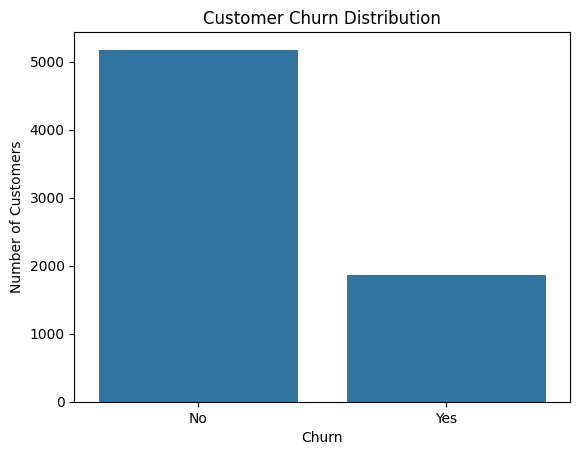

In [4]:
#target class distribution
print("Customer churn distribution:")
print(df['Churn'].value_counts())

print("\nChurn percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

sns.countplot(data=df, x='Churn')

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [5]:
#handling quality issues

print("TotalCharges data type:")
print(df['TotalCharges'].dtype)

print("\nBlank TotalCharges values:")
print((df['TotalCharges'].str.strip() == '').sum())

TotalCharges data type:
object

Blank TotalCharges values:
11


In [7]:
# Remove customerID
df = df.drop('customerID', axis=1)

# Separate features and target
X = df.drop('Churn', axis=1)
y = df['Churn']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7043, 19)
Target: (7043,)


In [8]:
# train test splitting

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (5634, 19)
Testing data: (1409, 19)

Training target distribution:
Churn
No     4139
Yes    1495
Name: count, dtype: int64

Testing target distribution:
Churn
No     1035
Yes     374
Name: count, dtype: int64


In [9]:
# Separate numerical and categorical columns

num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

print("Numerical columns:")
print(list(num_cols))

print("\nCategorical columns:")
print(list(cat_cols))

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']


In [10]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Prepare numerical and categorical data
num_transformer = StandardScaler()
cat_transformer = OneHotEncoder(handle_unknown='ignore')

# Combine both of the transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [11]:
# Learn preprocessing from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to testing data
X_test_processed = preprocessor.transform(X_test)

print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)


Training data: (5634, 5320)
Testing data: (1409, 5320)


In [13]:
#importing the model
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Create the logistic regression model
model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

print("Logistic Regression model created.")

Logistic Regression model created.


In [14]:
#training the model
model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [15]:
# Predict churn for testing data
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'Yes' 'No' 'No']


In [16]:
#import metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label='Yes')
recall = recall_score(y_test, y_pred, pos_label='Yes')
f1 = f1_score(y_test, y_pred, pos_label='Yes')

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.794180269694819
Precision: 0.63125
Recall: 0.5401069518716578
F1 Score: 0.5821325648414986

Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.89      0.86      1035
         Yes       0.63      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409



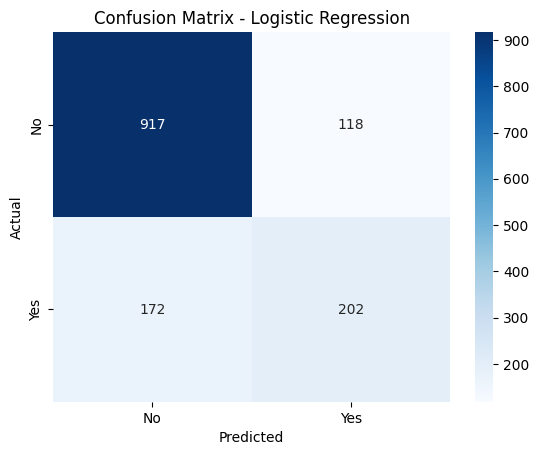

In [17]:
#confusin matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=['No', 'Yes'])

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Observations:

1. Logistic Regression was used as the baseline
   classification model.

2. The model was evaluated using accuracy,
   precision, recall and F1-score.

3. The confusion matrix was used to understand
   correct and incorrect predictions.

4. Recall is important because we want to identify
   as many customers who are likely to churn as possible.

5. The baseline results will be used to compare
   performance with other models.

In [18]:
#Training svm machine
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

# Create the SVM model
svm_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', SVC(
        kernel='rbf',
        C=1,
        gamma='scale',
        probability=True,
        random_state=42
    ))
])

# Train the model
svm_model.fit(X_train, y_train)

print("SVM model training completed!")

SVM model training completed!


In [19]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

# Trying three different SVM configurations
settings = [
    {'kernel': 'linear', 'C': 1},
    {'kernel': 'rbf', 'C': 1, 'gamma': 'scale'},
    {'kernel': 'rbf', 'C': 10, 'gamma': 'scale'}
]

for setting in settings:

    temp_model = Pipeline([
        ('preprocessing', preprocessor),
        ('classifier', SVC(
            **setting,
            probability=True,
            random_state=42
        ))
    ])

    temp_model.fit(X_train, y_train)

    temp_pred = temp_model.predict(X_test)

    print("\nSettings:", setting)
    print("Accuracy:", accuracy_score(y_test, temp_pred))
    print("Precision:", precision_score(y_test, temp_pred, pos_label='Yes'))
    print("Recall:", recall_score(y_test, temp_pred, pos_label='Yes'))
    print("F1 Score:", f1_score(y_test, temp_pred, pos_label='Yes'))


Settings: {'kernel': 'linear', 'C': 1}
Accuracy: 0.7920511000709723
Precision: 0.6231003039513677
Recall: 0.5481283422459893
F1 Score: 0.5832147937411095

Settings: {'kernel': 'rbf', 'C': 1, 'gamma': 'scale'}
Accuracy: 0.7934705464868701
Precision: 0.6466431095406361
Recall: 0.4893048128342246
F1 Score: 0.5570776255707762

Settings: {'kernel': 'rbf', 'C': 10, 'gamma': 'scale'}
Accuracy: 0.7849538679914834
Precision: 0.6047197640117994
Recall: 0.5481283422459893
F1 Score: 0.5750350631136045


In [20]:
# Predict churn
svm_pred = svm_model.predict(X_test)

print("First 20 predictions:")
print(svm_pred[:20])

First 20 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'Yes' 'No' 'No']


In [21]:
from sklearn.metrics import classification_report

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))

print("SVM Precision:",
      precision_score(y_test, svm_pred, pos_label='Yes'))

print("SVM Recall:",
      recall_score(y_test, svm_pred, pos_label='Yes'))

print("SVM F1 Score:",
      f1_score(y_test, svm_pred, pos_label='Yes'))

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))

SVM Accuracy: 0.7934705464868701
SVM Precision: 0.6466431095406361
SVM Recall: 0.4893048128342246
SVM F1 Score: 0.5570776255707762

Classification Report:
              precision    recall  f1-score   support

          No       0.83      0.90      0.87      1035
         Yes       0.65      0.49      0.56       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



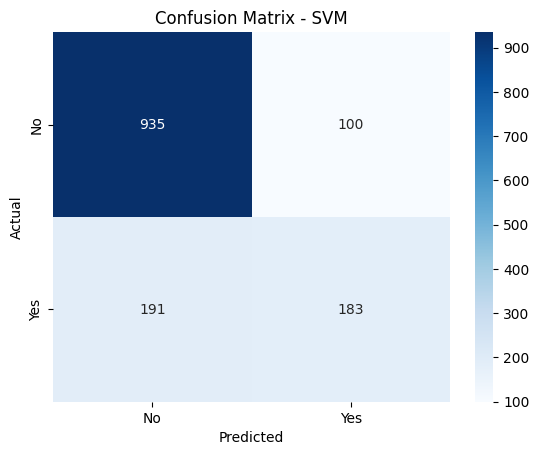

In [22]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, svm_pred, labels=['No', 'Yes'])

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

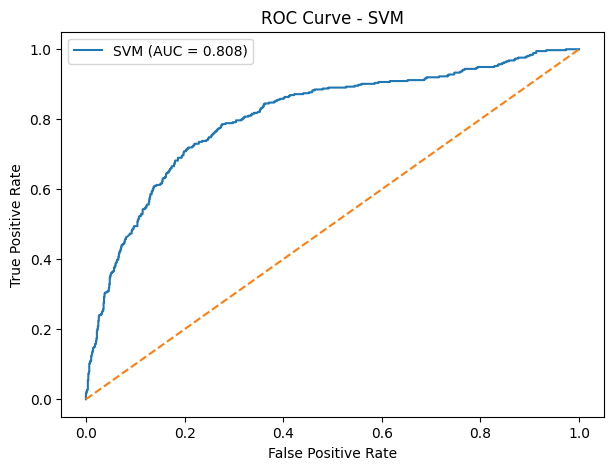

SVM ROC-AUC: 0.8082474359967966


In [23]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get churn probabilities
svm_prob = svm_model.predict_proba(X_test)[:, 1]

# Calculate ROC values
y_test_binary = (y_test == 'Yes').astype(int)

fpr, tpr, thresholds = roc_curve(y_test_binary, svm_prob)

# Calculate ROC-AUC
svm_auc = roc_auc_score(y_test_binary, svm_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label='SVM (AUC = %.3f)' % svm_auc)

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SVM")

plt.legend()
plt.show()

print("SVM ROC-AUC:", svm_auc)

In [25]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix

In [27]:
# Creating AdaBoost model
ada_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', AdaBoostClassifier(random_state=42))
])

print("AdaBoost model created successfully!")

AdaBoost model created successfully!


In [28]:
# Training the model
ada_model.fit(X_train, y_train)

print("AdaBoost model training completed!")

AdaBoost model training completed!


In [29]:
# Predict customer churn
ada_pred = ada_model.predict(X_test)

print("First 20 predictions:")
print(ada_pred[:20])

First 20 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'Yes' 'No' 'No']


In [30]:
# Calculate evaluation metrics
ada_accuracy = accuracy_score(y_test, ada_pred)

ada_precision = precision_score(y_test, ada_pred, pos_label='Yes')

ada_recall = recall_score(y_test, ada_pred, pos_label='Yes')

ada_f1 = f1_score(y_test, ada_pred, pos_label='Yes')

print("AdaBoost Accuracy:", ada_accuracy)
print("AdaBoost Precision:", ada_precision)
print("AdaBoost Recall:", ada_recall)
print("AdaBoost F1 Score:", ada_f1)

print("\nClassification Report:")
print(classification_report(y_test, ada_pred))

AdaBoost Accuracy: 0.8005677785663591
AdaBoost Precision: 0.6430769230769231
AdaBoost Recall: 0.5588235294117647
AdaBoost F1 Score: 0.597997138769671

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.64      0.56      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.80      1409



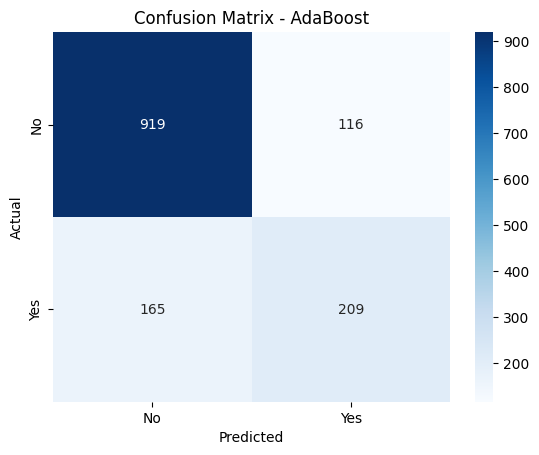

In [31]:
# Create confusion matrix
cm = confusion_matrix(y_test, ada_pred, labels=['No', 'Yes'])

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title("Confusion Matrix - AdaBoost")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [32]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [33]:
# Create logistic regression pipeline
lr_pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

print("Pipeline created successfully!")

Pipeline created successfully!


In [34]:
# Values to test
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}

In [35]:
# Create cross-validation strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create grid search
grid_search = GridSearchCV(
    lr_pipeline,
    param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1
)

# Train and find the best parameters
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1-score:", grid_search.best_score_)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan]
  warnings.warn(


Best parameters: {'classifier__C': 0.01}
Best cross-validation F1-score: nan


In [36]:
# Store the best model
best_model = grid_search.best_estimator_

# Make predictions
optimized_pred = best_model.predict(X_test)

print("Optimized model predictions:")
print(optimized_pred[:20])

Optimized model predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'Yes' 'No' 'No']


In [37]:
# Calculate evaluation metrics
optimized_accuracy = accuracy_score(y_test, optimized_pred)

optimized_precision = precision_score(
    y_test, optimized_pred, pos_label='Yes'
)

optimized_recall = recall_score(
    y_test, optimized_pred, pos_label='Yes'
)

optimized_f1 = f1_score(
    y_test, optimized_pred, pos_label='Yes'
)

print("Optimized Accuracy:", optimized_accuracy)
print("Optimized Precision:", optimized_precision)
print("Optimized Recall:", optimized_recall)
print("Optimized F1-score:", optimized_f1)

Optimized Accuracy: 0.7984386089425124
Optimized Precision: 0.6595744680851063
Optimized Recall: 0.49732620320855614
Optimized F1-score: 0.5670731707317073


In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [39]:
# Compare original and optimized models

comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Before Optimization': [
        accuracy,
        precision,
        recall,
        f1
    ],
    'After Optimization': [
        optimized_accuracy,
        optimized_precision,
        optimized_recall,
        optimized_f1
    ]
})

display(comparison)

,Metric,Before Optimization,After Optimization
0,Accuracy,0.794180,0.798439
1,Precision,0.631250,0.659574
2,Recall,0.540107,0.497326
3,F1-score,0.582133,0.567073


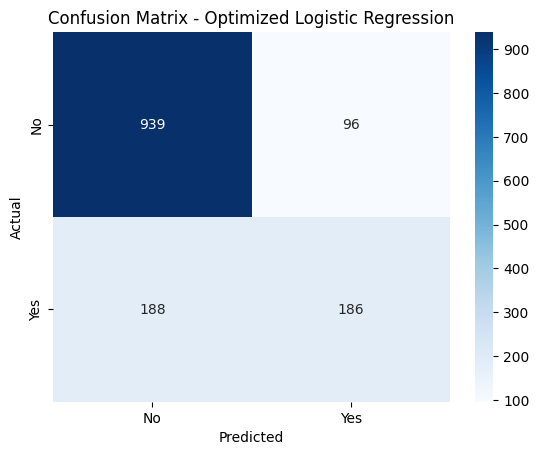

In [40]:
cm = confusion_matrix(
    y_test,
    optimized_pred,
    labels=['No', 'Yes']
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No', 'Yes'],
    yticklabels=['No', 'Yes']
)

plt.title("Confusion Matrix - Optimized Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()